# Native Gridded Import, Zonal Rainfall, and Grid Tools

This notebook imports real NOAA gridded products into DSS without Java, HEC-Vortex or
GDAL, processes the grids, and turns them into subbasin rainfall series for HEC-HMS. It
uses the `HmsDssGrid` wrappers around the optional `ras-commander-fast-dss` engine, which
run on the engine whatever `HmsDss.backend` is.

The study area is the HEC-HMS `tenk` sample basin (Illinois River above Lake Tenkiller,
Oklahoma and Arkansas). Its subbasins are located from the sample's own grid cell file.

**Example 1: import real sources.** The largest AORC storm of 2023 over tenk (23-24 March):

- MRMS multi-sensor QPE (Pass 2) as GRIB2, from NOAA's open data on AWS: 1-hour grids,
  and the 6-hour and 24-hour products with their accumulation windows;
- AORC v1.1 for the same hours, as NetCDF-4 (written by `HmsAorc.download` from NOAA's
  AORC Zarr store);
- the SHG lattice, an envelope, a shapefile's bounding box, the resampling methods and
  the thread count.

**Example 2: grid tools and zonal rainfall.** On the imported grids: sanitizer, constant
and raster calculators, clipper, normalizer (MRMS hourly pattern scaled to AORC event
totals), time shift, time-step resampling, window/nearest/minimum-maximum reads, and
zonal statistics written as DSS time series for each subbasin (all eight statistics).
Then SNODAS snow products for the February 2021 winter storm, with the engine's header
timing and HEC-Vortex's timing.

**Prerequisites**
- `pip install "hms-commander[dss,aorc,gis]"` and `ras-commander` (for its MRMS downloader)
- HEC-HMS 4.13 with its sample projects (for the tenk cell file); no HEC-HMS run is made
- Internet access: AWS S3 (MRMS, AORC) and NSIDC (SNODAS), about 120 MB in all

**Estimated time**: 3-6 minutes, most of it downloading.

In [1]:
# pip install "hms-commander[dss,aorc,gis]" ras-commander

## Setup

In [2]:
from pathlib import Path
from importlib.metadata import version
import datetime as dt
import hashlib
import logging
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hms_commander import HmsAorc, HmsDss, HmsDssGrid, HmsExamples, HmsGrid

logging.getLogger().setLevel(logging.ERROR)
for _name in list(logging.root.manager.loggerDict):
    if _name.startswith(("hms_commander", "ras_commander")):
        logging.getLogger(_name).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)

work = Path.cwd() / "working" / "23_native_gridded"


def reason(exc):
    # The engine's refusal, from the word "refused" on (its message also names the input path)
    text = str(exc)
    return text[text.find("refused"):] if "refused" in text else type(exc).__name__
work.mkdir(parents=True, exist_ok=True)

print(f"ras-commander-fast-dss {version('ras-commander-fast-dss')}")
print(f"DSS backend for the HmsDss reads below: {HmsDss.get_backend()}")
features = HmsDssGrid.get_features()
display(pd.Series(features, name="available").to_frame())

ras-commander-fast-dss 0.1.2
DSS backend for the HmsDss reads below: java


,available
grid_to_point,True
grid_tools,True
gridded_accumulation_window,True
gridded_import,True
gridded_netcdf,True
gridded_time_tools,True
gridded_zarr,True


## The tenk subbasins as zones

The sample's `regions/hrapcells` lists each subbasin's cells by HRAP index and area.
`HmsGrid.get_cell_polygons` places those cells on the map. The union of each subbasin's
cells is its zone. Whole HRAP cells (about 16.5 km2 each) are used, so a zone is larger
than its subbasin wherever a cell is only partly inside it; the table compares the two
areas. The zones are written as a shapefile on the SHG lattice's CRS (EPSG:5070).

In [3]:
tenk = Path(HmsExamples.extract_project("tenk", version="4.13", output_path=work / "tenk_source"))
cells = HmsGrid.get_cell_polygons(tenk / "regions" / "hrapcells", "HRAP")
zones = (cells.to_crs(HmsGrid.SHG_CRS).dissolve("subbasin").reset_index()
         .rename(columns={"subbasin": "NAME"})[["NAME", "geometry"]])
zones_file = work / "tenk_subbasins.shp"
zones.to_file(zones_file)

areas = pd.DataFrame({
    "cells": cells.groupby("subbasin").size(),
    "area in cell file (km2)": cells.groupby("subbasin")["area"].sum(),
    "zone area (km2)": zones.set_index("NAME").area / 1e6,
}).round(1)
display(areas)

CELL = 2000.0
x0, y0, x1, y1 = zones.total_bounds
pad = 4 * CELL
envelope = (float(np.floor((x0 - pad) / CELL) * CELL), float(np.floor((y0 - pad) / CELL) * CELL),
            float(np.ceil((x1 + pad) / CELL) * CELL), float(np.ceil((y1 + pad) / CELL) * CELL))
w, s, e, n = zones.to_crs(4326).total_bounds
bounds = tuple(float(round(v, 2)) for v in (w - 0.1, s - 0.1, e + 0.1, n + 0.1))
print(f"SHG envelope (m): {envelope}")
print(f"Download bounds (W, S, E, N): {bounds}")

,cells,area in cell file (km2),zone area (km2)
113,78,845.2,1213.6
127,86,928.6,1374.2
85,84,854.6,1350.1
86,129,1554.5,2040.8


SHG envelope (m): (70000.0, 1378000.0, 184000.0, 1494000.0)
Download bounds (W, S, E, N): (-95.23, 35.44, -93.94, 36.5)


## Example 1: Import Real Sources

### Choose the event

`HmsAorc.get_storm_catalog` ranks the 2023 storms over the basin from AORC. The largest is
used for every source below.

In [4]:
storms = HmsAorc.get_storm_catalog(bounds, year=2023)
storm = storms.sort_values("rank").iloc[0]
display(storms.sort_values("rank").head(5)[["storm_id", "start_time", "end_time",
                                             "duration_hours", "total_depth_in"]])
print(f"Largest 2023 storm: {storm['start_time']} to {storm['end_time']} (UTC), "
      f"{storm['total_depth_in']:.2f} in basin average")
# Hours used below: the 30 hours ending 25 Mar 2023 00:00 UTC (stamps are period ends)
FIRST_END, LAST_END = "2023-03-23 19:00", "2023-03-25 00:00"

,storm_id,start_time,end_time,duration_hours,total_depth_in
10,11,2023-03-23 20:00:00,2023-03-24 20:00:00,25,2.443
3,4,2023-02-07 16:00:00,2023-02-09 06:00:00,39,2.125
7,8,2023-03-02 18:00:00,2023-03-03 15:00:00,22,1.907
32,33,2023-10-28 13:00:00,2023-10-30 04:00:00,40,1.687
35,36,2023-12-24 11:00:00,2023-12-25 07:00:00,21,1.637


Largest 2023 storm: 2023-03-23 20:00:00 to 2023-03-24 20:00:00 (UTC), 2.44 in basin average


### MRMS QPE, 1-hour, as GRIB2

`ras_commander.precip.PrecipMrms.download` fetches full-domain MRMS files from NOAA's open
data on AWS. `HmsDssGrid.list_variables` shows what a file offers, and
`HmsDssGrid.import_gridded(product="mrms_qpe")` selects the QPE variable. Each record
holds the depth over the hour ending at the file's time (PER-CUM, mm), warped to 2 km SHG
cells inside the envelope.

In [5]:
from ras_commander.precip import PrecipMrms

mrms_dir = work / "mrms"
mrms_01h = PrecipMrms.download(bounds, FIRST_END, LAST_END, mrms_dir / "01H",
                               product="MultiSensor_QPE_01H_Pass2")
print(f"{len(mrms_01h)} files, {mrms_01h[0].name} to {mrms_01h[-1].name}")
print(f"Variables: {HmsDssGrid.list_variables(mrms_01h[0])}")

mrms_dss = work / "mrms_01h.dss"
mrms_dss.unlink(missing_ok=True)
result = HmsDssGrid.import_gridded(
    mrms_01h, mrms_dss, product="mrms_qpe", target_crs="SHG", cell_size=CELL,
    method="bilinear", envelope=envelope, parts={"A": "SHG", "B": "TENK", "F": "MRMS-PASS2"})
first = result.records[0]
print(f"\n{len(result.records)} records; first {first['pathname']}")
print(f"{first['data_type']} {first['units']}, {first['nx']} x {first['ny']} cells of "
      f"{first['cell_size']:.0f} m, lower-left cell ({first['lower_left_cell_x']}, "
      f"{first['lower_left_cell_y']})")

30 files, MRMS_MultiSensor_QPE_01H_Pass2_00.00_20230323-190000.grib2 to MRMS_MultiSensor_QPE_01H_Pass2_00.00_20230325-000000.grib2
Variables: ['MultiSensor_QPE_01H_Pass2_altitude_above_msl']



30 records; first /SHG/TENK/PRECIPITATION/23MAR2023:1800/23MAR2023:1900/MRMS-PASS2/
PER-CUM MM, 57 x 58 cells of 2000 m, lower-left cell (35, 689)


### Accumulation windows: the 6-hour and 24-hour products

A 6-hour or 24-hour MRMS file holds the depth over the hours ending at its time, but the
GRIB2 field does not state the period as a time range. The engine refuses it unless the
call states the window: `window_rule="accumulation:06H"`. The engine then checks the
statement against the variable name and the file name (`accumulation_stated_by`) and
reports overlaps or gaps between consecutive records. The 6-hour files below are taken
every 6 hours, so their windows tile the event.

The 6-hour grids are compared with the sum of the six 1-hour grids in each window,
computed by `HmsDssGrid.read_window`.

In [6]:
mrms_06h = PrecipMrms.download(bounds, "2023-03-24 00:00", LAST_END, mrms_dir / "06H",
                               product="MultiSensor_QPE_06H_Pass2")
mrms_06h = [f for f in mrms_06h if f.name.endswith(("-000000.grib2", "-060000.grib2",
                                                    "-120000.grib2", "-180000.grib2"))]
mrms_24h = PrecipMrms.download(bounds, LAST_END, LAST_END, mrms_dir / "24H",
                               product="MultiSensor_QPE_24H_Pass2")

six_dss = work / "mrms_06h.dss"
six_dss.unlink(missing_ok=True)
try:
    HmsDssGrid.import_gridded(mrms_06h, six_dss, product="mrms_qpe", target_crs="SHG",
                              cell_size=CELL, envelope=envelope)
except Exception as exc:
    print(f"Without a window rule, {type(exc).__name__}: {reason(exc)[:200]}...")

six = HmsDssGrid.import_gridded(
    mrms_06h, six_dss, product="mrms_qpe", target_crs="SHG", cell_size=CELL,
    envelope=envelope, window_rule="accumulation:06H",
    parts={"A": "SHG", "B": "TENK", "F": "MRMS-PASS2-06H"})
day_dss = work / "mrms_24h.dss"
day_dss.unlink(missing_ok=True)
day = HmsDssGrid.import_gridded(
    mrms_24h, day_dss, product="mrms_qpe", target_crs="SHG", cell_size=CELL,
    envelope=envelope, window_rule="accumulation:24H",
    parts={"A": "SHG", "B": "TENK", "F": "MRMS-PASS2-24H"})

rows = []
one_hour_series = HmsDss.get_catalog(mrms_dss)[0]
for rec in six.records + day.records:
    target = six_dss if rec in six.records else day_dss
    grid = HmsDss.read_grid(target, rec["pathname"])
    start = grid["start_time"].strftime("%d%b%Y:%H%M").upper()
    end = grid["end_time"].strftime("%d%b%Y:%H%M").upper()
    summed = np.asarray(HmsDssGrid.read_window(mrms_dss, one_hour_series, start, end).data)
    ok = np.isfinite(summed) & np.isfinite(grid["data"])
    rows.append({"record": "/".join(rec["pathname"].split("/")[4:7]),
                 "stated by": rec["accumulation_stated_by"],
                 "gap before": rec["gap_before"], "overlaps earlier": rec["overlaps_earlier"],
                 "product mean (mm)": float(grid["data"][ok].mean()),
                 "sum of 1-hour (mm)": float(summed[ok].mean()),
                 "max |difference| (mm)": float(np.abs(summed - grid["data"])[ok].max())})
display(pd.DataFrame(rows).round(3))

Without a window rule, DssUnsupportedRecordError: refused time of MultiSensor_QPE_06H_Pass2_altitude_above_msl: precipitation at an instant states no period, so its D and E parts cannot say when the depth fell. Give the frame an explicit (start, end)...


,record,stated by,gap before,overlaps earlier,product mean (mm),sum of 1-hour (mm),max |difference| (mm)
0,23MAR2023:1800/23MAR2023:2400/MRMS-PASS2-06H,variable+file_name,False,False,11.764,11.764,0.0
1,24MAR2023:0000/24MAR2023:0600/MRMS-PASS2-06H,variable+file_name,False,False,15.808,15.808,0.0
2,24MAR2023:0600/24MAR2023:1200/MRMS-PASS2-06H,variable+file_name,False,False,13.837,13.837,0.0
3,24MAR2023:1200/24MAR2023:1800/MRMS-PASS2-06H,variable+file_name,False,False,18.354,18.354,0.0
4,24MAR2023:1800/24MAR2023:2400/MRMS-PASS2-06H,variable+file_name,False,False,1.792,1.792,0.0
5,24MAR2023:0000/24MAR2023:2400/MRMS-PASS2-24H,variable+file_name,False,False,49.791,49.791,0.0


### AORC for the same hours, as NetCDF-4

`HmsAorc.download` writes the AORC v1.1 values for the box and hours to NetCDF-4. A file
named `*AORC*APCP*.nc4` holding `APCP_surface` is read by the engine as AORC: each value
is the depth over the hour ending at its time.

In [7]:
aorc_nc = work / "AORC_APCP_tenk_mar2023.nc4"
HmsAorc.download(bounds=bounds, start_time=FIRST_END, end_time=LAST_END, output_path=aorc_nc)
aorc_dss = work / "aorc_2023.dss"
aorc_dss.unlink(missing_ok=True)
aorc = HmsDssGrid.import_gridded(
    aorc_nc, aorc_dss, variable="APCP_surface", target_crs="SHG", cell_size=CELL,
    method="bilinear", envelope=envelope, parts={"A": "SHG", "B": "TENK", "F": "AORC"})
print(f"{len(aorc.records)} AORC records: {aorc.pathnames[0]} ... {aorc.pathnames[-1]}")

EVENT = ("23MAR2023:1800", "25MAR2023:0000")
mrms_total = HmsDssGrid.read_window(mrms_dss, HmsDss.get_catalog(mrms_dss)[0], *EVENT)
aorc_total = HmsDssGrid.read_window(aorc_dss, aorc.pathnames[0], *EVENT)
print(f"Event total over the envelope: MRMS {np.nanmean(mrms_total.data):.1f} mm, "
      f"AORC {np.nanmean(aorc_total.data):.1f} mm (cell means)")

30 AORC records: /SHG/TENK/PRECIPITATION/23MAR2023:1800/23MAR2023:1900/AORC/ ... /SHG/TENK/PRECIPITATION/24MAR2023:2300/24MAR2023:2400/AORC/
Event total over the envelope: MRMS 61.6 mm, AORC 61.6 mm (cell means)


### Envelope or shapefile, resampling method and threads

- `shapefile=` clips to the bounding box of the shapefile's features, in its `.prj` CRS.
  It is not a polygon mask (as in HEC-Vortex).
- `method=` is `"near"`, `"bilinear"` (default) or `"average"`.
- `threads=None` (the default) uses every core; `threads=1` one worker. The records are the
  same whatever the count.

In [8]:
variants = {}
for label, kwargs in {
    "envelope, bilinear, all cores": dict(envelope=envelope, method="bilinear"),
    "envelope, bilinear, threads=1": dict(envelope=envelope, method="bilinear", threads=1),
    "envelope, near": dict(envelope=envelope, method="near"),
    "envelope, average": dict(envelope=envelope, method="average"),
    "shapefile bounding box, bilinear": dict(shapefile=zones_file, method="bilinear"),
}.items():
    target = work / f"variant_{len(variants)}.dss"
    target.unlink(missing_ok=True)
    res = HmsDssGrid.import_gridded(mrms_01h, target, product="mrms_qpe", target_crs="SHG",
                                    cell_size=CELL, parts={"A": "SHG", "B": "TENK", "F": "MRMS"},
                                    **kwargs)
    total = HmsDssGrid.read_window(target, res.pathnames[0], *EVENT)
    variants[label] = (target, res, total)

rows = []
for label, (target, res, total) in variants.items():
    rec = res.records[0]
    rows.append({"import": label, "cells": f"{rec['nx']} x {rec['ny']}",
                 "lower-left cell": (rec["lower_left_cell_x"], rec["lower_left_cell_y"]),
                 "event mean (mm)": float(np.nanmean(total.data)),
                 "event max (mm)": float(np.nanmax(total.data))})
display(pd.DataFrame(rows).round(2))

# All cores against one thread: compare every record
a_file, a_res, _ = variants["envelope, bilinear, all cores"]
b_file, b_res, _ = variants["envelope, bilinear, threads=1"]
same = sum(np.array_equal(HmsDss.read_grid(a_file, p)["data"], HmsDss.read_grid(b_file, p)["data"],
                          equal_nan=True) for p in a_res.pathnames)
a_bytes, b_bytes = a_file.read_bytes(), b_file.read_bytes()
differing = sum(x != y for x, y in zip(a_bytes, b_bytes))
print(f"All cores against threads=1: {same} of {len(a_res.pathnames)} records have identical cells; "
      f"the catalogs match: {HmsDss.get_catalog(a_file) == HmsDss.get_catalog(b_file)}.")
print(f"The files ({len(a_bytes):,} and {len(b_bytes):,} bytes) differ in {differing} bytes.")

# A DSS file records when each record was written; the engine's own catalog shows it.
import ras_commander_fast_dss as fast_dss  # direct engine call, for the write times only
written = pd.DataFrame({"all cores": fast_dss.get_catalog(a_file)["last_write"].iloc[:3].values,
                        "threads=1": fast_dss.get_catalog(b_file)["last_write"].iloc[:3].values})
print("Write times of the first three records (the runs were made one after the other):")
display(written)

,import,cells,lower-left cell,event mean (mm),event max (mm)
0,"envelope, bilinear, all cores",57 x 58,"(35, 689)",61.56,141.54
1,"envelope, bilinear, threads=1",57 x 58,"(35, 689)",61.56,141.54
2,"envelope, near",57 x 58,"(35, 689)",61.59,145.80
3,"envelope, average",57 x 58,"(35, 689)",61.56,143.12
4,"shapefile bounding box, bilinear",49 x 50,"(39, 693)",58.59,135.44


All cores against threads=1: 30 of 30 records have identical cells; the catalogs match: True.
The files (368,360 and 368,360 bytes) differ in 212 bytes.
Write times of the first three records (the runs were made one after the other):


,all cores,threads=1
0,2026-11-12 16:20:48.700,2026-11-12 16:20:55.693
1,2026-11-12 16:20:48.901,2026-11-12 16:20:55.886
2,2026-11-12 16:20:49.119,2026-11-12 16:20:56.093


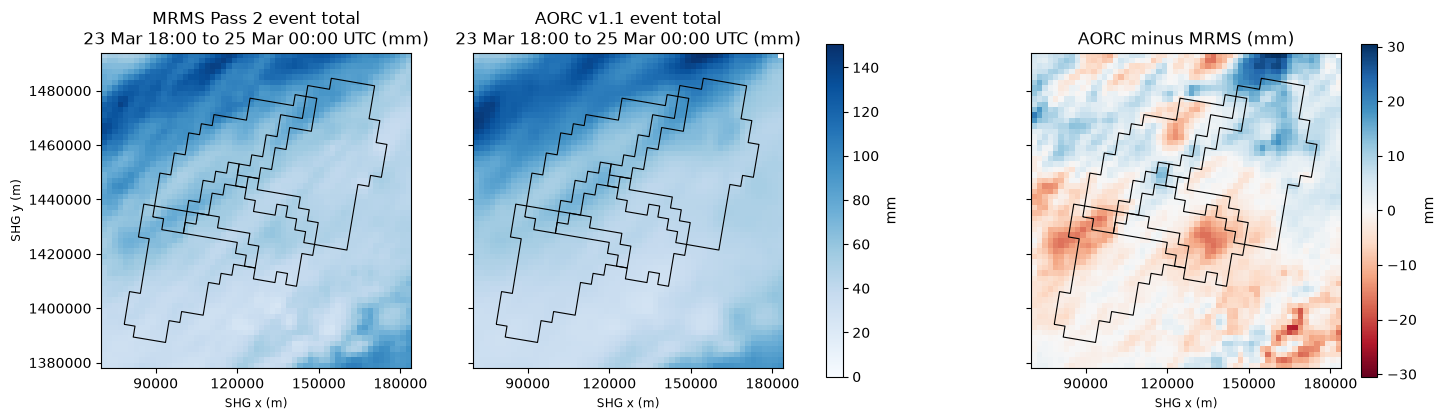

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), sharex=True, sharey=True)
panels = [("MRMS Pass 2 event total", mrms_total), ("AORC v1.1 event total", aorc_total)]
vmax = max(np.nanmax(p[1].data) for p in panels)
def extent(win):
    return (win.lower_left_cell_x * CELL, (win.lower_left_cell_x + win.nx) * CELL,
            win.lower_left_cell_y * CELL, (win.lower_left_cell_y + win.ny) * CELL)
for ax, (title, win) in zip(axes[:2], panels):
    im = ax.imshow(np.asarray(win.data), origin="lower", extent=extent(win), cmap="Blues",
                   vmin=0, vmax=vmax)
    zones.boundary.plot(ax=ax, color="k", linewidth=0.8)
    ax.set_title(f"{title}\n23 Mar 18:00 to 25 Mar 00:00 UTC (mm)")
fig.colorbar(im, ax=axes[:2], shrink=0.8, label="mm")
diff = np.asarray(aorc_total.data) - np.asarray(mrms_total.data)
lim = np.nanmax(np.abs(diff))
im2 = axes[2].imshow(diff, origin="lower", extent=extent(mrms_total), cmap="RdBu", vmin=-lim, vmax=lim)
zones.boundary.plot(ax=axes[2], color="k", linewidth=0.8)
axes[2].set_title("AORC minus MRMS (mm)")
fig.colorbar(im2, ax=axes[2], shrink=0.8, label="mm")
for ax in axes:
    ax.set_xlabel("SHG x (m)")
    ax.set_ylabel("")
    ax.ticklabel_format(style="plain")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
axes[0].set_ylabel("SHG y (m)")
plt.show()

## Example 2: Grid Tools and Zonal Rainfall

Every tool reads a DSS file and writes a new one; its result lists the records written.
The output's A, B and F parts are given with `parts` (`"F": "*"` keeps the source's F
part).

### Sanitizer and constant calculator

`sanitize` replaces valid cells at or beyond thresholds (missing by default). Both
thresholds are inclusive, so a minimum of 0 would remove every dry cell; here
`minimum=-0.001` removes negative depths and `maximum=150` hourly depths of 150 mm or more.
The count of changed cells is reported even when it is zero. `calculate` applies one constant to
every valid cell, here mm to inches.

In [10]:
keep = {"A": "SHG", "B": "TENK", "F": "*"}
clean_dss = work / "mrms_sanitized.dss"
inch_dss = work / "mrms_inches.dss"
for f in (clean_dss, inch_dss):
    f.unlink(missing_ok=True)
HmsDssGrid.sanitize(mrms_dss, clean_dss, minimum=-0.001, maximum=150.0, parts=keep)
changed = 0
for p in HmsDss.get_catalog(mrms_dss):
    before, after = HmsDss.read_grid(mrms_dss, p)["data"], HmsDss.read_grid(clean_dss, p)["data"]
    changed += int(np.sum(np.isfinite(before) != np.isfinite(after)))
print(f"Cells the sanitizer changed: {changed}")

inches = HmsDssGrid.calculate(clean_dss, inch_dss, divide=25.4, units="IN", parts=keep)
rec = inches.records[0]
print(f"calculate: {len(inches.records)} records in {rec['units']} "
      f"(source {rec['source_units']}); same cells divided by 25.4")

Cells the sanitizer changed: 0


calculate: 30 records in IN (source MM); same cells divided by 25.4


### Clipper and time-step resampler

`clip` subsets grids to an envelope in their own CRS, by nearest neighbour, on whole cells.
`resample_times` aggregates to a fixed step; for PER-CUM depths each window holds the
volume of the hours inside it. Windows start at midnight of the series' first day, so a
window that begins before the first record is written with every cell missing, as in
HEC-Vortex.

In [11]:
clip_dss = work / "mrms_clip.dss"
three_dss = work / "mrms_3h.dss"
for f in (clip_dss, three_dss):
    f.unlink(missing_ok=True)
sub = zones[zones["NAME"] == "86"].total_bounds
clip_env = (float(np.floor(sub[0] / CELL) * CELL), float(np.floor(sub[1] / CELL) * CELL),
            float(np.ceil(sub[2] / CELL) * CELL), float(np.ceil(sub[3] / CELL) * CELL))
clipped = HmsDssGrid.clip(clean_dss, clip_dss, envelope=clip_env, envelope_crs="SHG", parts=keep)
rec = clipped.records[0]
print(f"clip to subbasin 86's box: {rec['nx']} x {rec['ny']} cells from lower-left "
      f"({rec['lower_left_cell_x']}, {rec['lower_left_cell_y']})")

three = HmsDssGrid.resample_times(clean_dss, three_dss, 180, parts=keep)
print(f"\nresample_times to 180 minutes: {len(three.pathnames)} records, "
      f"{three.windows_every_cell_missing} written with every cell missing")
for p in three.pathnames[:8]:
    print(f"  {p}")
total_1h = HmsDssGrid.read_window(clean_dss, HmsDss.get_catalog(clean_dss)[0], *EVENT)
total_3h = HmsDssGrid.read_window(three_dss, three.pathnames[0], *EVENT)
print(f"Event volume, 1-hour series {np.nansum(total_1h.data):.1f} mm-cells, "
      f"3-hour series {np.nansum(total_3h.data):.1f} mm-cells")

clip to subbasin 86's box: 29 x 33 cells from lower-left (59, 710)

resample_times to 180 minutes: 16 records, 6 written with every cell missing
  /SHG/TENK/PRECIPITATION/23MAR2023:0000/23MAR2023:0300/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:0300/23MAR2023:0600/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:0600/23MAR2023:0900/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:0900/23MAR2023:1200/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:1200/23MAR2023:1500/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:1500/23MAR2023:1800/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:1800/23MAR2023:2100/MRMS-PASS2/
  /SHG/TENK/PRECIPITATION/23MAR2023:2100/23MAR2023:2400/MRMS-PASS2/
Event volume, 1-hour series 203502.6 mm-cells, 3-hour series 203502.6 mm-cells


### Normalizer: MRMS timing, AORC totals

`normalize` scales each interval's source grids so their total matches the normals'
total in that interval, cell by cell. With the whole 30-hour event as one interval and
AORC as the normals, the result keeps MRMS's hour-by-hour pattern and AORC's event depth.
A cell whose normal is missing is written as missing (reported, not hidden).

In [12]:
norm_dss = work / "mrms_normalized_to_aorc.dss"
norm_dss.unlink(missing_ok=True)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    norm = HmsDssGrid.normalize(
        clean_dss, aorc_dss, norm_dss, start=dt.datetime(2023, 3, 23, 18),
        end=dt.datetime(2023, 3, 25, 0), interval=dt.timedelta(hours=30),
        parts={"A": "SHG", "B": "TENK", "F": "MRMS-NORMALIZED-AORC"})
print(f"normalize: {len(norm.pathnames)} records; valid cells made missing by a missing "
      f"normal: {norm.cells_made_missing_by_normal}")
for w_ in caught:
    print(f"  warning: {str(w_.message).split(': ', 1)[-1]}")
norm_total = HmsDssGrid.read_window(norm_dss, norm.pathnames[0], *EVENT)
d = np.asarray(norm_total.data) - np.asarray(aorc_total.data)
print(f"Normalized event total against AORC: max |difference| {np.nanmax(np.abs(d)):.1e} mm")

normalize: 30 records; valid cells made missing by a missing normal: 30
Normalized event total against AORC: max |difference| 6.1e-05 mm


### Time shifter, window reads and the raster calculator

- `shift_times` moves every record by a fixed duration. It is plain arithmetic on the
  stamps, not a time-zone conversion. Here -6 hours expresses the UTC stamps in Central
  Standard Time (UTC-6). On 23-24 March 2023 Oklahoma clocks were on daylight time
  (UTC-5); a fixed shift does not follow clock changes.
- `read_nearest`, `read_min_max` and `series_info` read without writing.
- `calculate_raster` combines each grid with a raster resampled to it; here AORC's 24 March
  daily total minus MRMS's (both from `resample_times` to 1,440 minutes).

In [13]:
shift_dss = work / "mrms_cst.dss"
shift_dss.unlink(missing_ok=True)
shifted = HmsDssGrid.shift_times(clean_dss, shift_dss, shift=dt.timedelta(hours=-6), parts=keep)
print(f"shift_times -6 h: {shifted.records[0]['source']}\n               -> {shifted.pathnames[0]}")

series = HmsDssGrid.series_info(clean_dss, HmsDss.get_catalog(clean_dss)[0])
print(f"\nseries_info: {series['series']}, {series['records']} records, "
      f"{series['start']} to {series['end']}, {series['data_type']} {series['units']}")
nearest = HmsDssGrid.read_nearest(clean_dss, HmsDss.get_catalog(clean_dss)[0], "24MAR2023:1230")
print(f"read_nearest 24MAR2023:1230 -> the record {nearest.start} to {nearest.end}")
low, high = HmsDssGrid.read_min_max(clean_dss, HmsDss.get_catalog(clean_dss)[0], *EVENT)
print(f"read_min_max: largest hourly depth in any cell {np.nanmax(high.data):.1f} mm")

daily = {}
for label, src in (("MRMS", clean_dss), ("AORC", aorc_dss)):
    target = work / f"daily_{label.lower()}.dss"
    target.unlink(missing_ok=True)
    daily[label] = (target, HmsDssGrid.resample_times(src, target, 1440,
                                                      parts={"A": "SHG", "B": "TENK", "F": label}))
day_m = next(p for p in daily["MRMS"][1].pathnames if "/24MAR2023:0000/" in p)
day_a = next(p for p in daily["AORC"][1].pathnames if "/24MAR2023:0000/" in p)
diff_dss = work / "aorc_minus_mrms_24mar.dss"
diff_dss.unlink(missing_ok=True)
diff = HmsDssGrid.calculate_raster(daily["AORC"][0], daily["MRMS"][0], diff_dss, operation="subtract",
                                   raster_variable=day_m, variables=[day_a],
                                   parts={"A": "SHG", "B": "TENK", "F": "AORC-MINUS-MRMS"})
g = HmsDss.read_grid(diff_dss, diff.pathnames[0])
print(f"\ncalculate_raster {diff.pathnames[0]}:")
print(f"  AORC minus MRMS on 24 Mar: mean {np.nanmean(g['data']):.2f} mm, "
      f"range {np.nanmin(g['data']):.1f} to {np.nanmax(g['data']):.1f} mm")

shift_times -6 h: /SHG/TENK/PRECIPITATION/23MAR2023:1800/23MAR2023:1900/MRMS-PASS2/
               -> /SHG/TENK/PRECIPITATION/23MAR2023:1200/23MAR2023:1300/MRMS-PASS2/

series_info: /SHG/TENK/PRECIPITATION/*/*/MRMS-PASS2/, 30 records, 23MAR2023:1800 to 24MAR2023:2400, PER-CUM MM
read_nearest 24MAR2023:1230 -> the record 24MAR2023:1200 to 24MAR2023:1300
read_min_max: largest hourly depth in any cell 33.9 mm

calculate_raster /SHG/TENK/PRECIPITATION/24MAR2023:0000/24MAR2023:2400/AORC-MINUS-MRMS/:
  AORC minus MRMS on 24 Mar: mean -0.44 mm, range -23.8 to 17.7 mm


### Zonal statistics and subbasin rainfall series

`zone_masks` lists each zone's cells (a cell belongs to a zone if its centre does).
`zonal_statistics` returns the statistics as a table, and `grid_to_point` writes them as
DSS time series, one per zone and statistic, with the zone name as the B part, ready for
HEC-HMS gages. All eight statistics are written here; `area_weighted=True` adds the mean
weighted by each cell's share inside the zone.

In [14]:
from ras_commander_fast_dss.gridded import STATISTICS  # the engine's list of statistic names

masks = HmsDssGrid.zone_masks(clean_dss, zones_file, "NAME")
print("Cells per zone:", {k: len(v) for k, v in masks.items()})
print("Statistics:", STATISTICS)

table = HmsDssGrid.zonal_statistics(clean_dss, zones_file, "NAME", area_weighted=True)
display(table[table["start"] == pd.Timestamp("2023-03-24 12:00")])

gages = {}
for label, src in (("MRMS", clean_dss), ("AORC", aorc_dss), ("MRMS-NORMALIZED", norm_dss)):
    target = work / f"subbasin_rain_{label.lower()}.dss"
    target.unlink(missing_ok=True)
    gages[label] = (target, HmsDssGrid.grid_to_point(src, zones_file, "NAME", target,
                                                     statistics=list(STATISTICS),
                                                     parts={"A": "TENK", "F": label}))
target, res = gages["MRMS"]
print(f"\ngrid_to_point (MRMS): {len(res.pathnames)} series, for example")
for p in res.pathnames[:8]:
    print(f"  {p}")

Cells per zone: {'113': 301, '127': 344, '85': 337, '86': 509}
Statistics: ('average', 'min', 'max', 'median', 'q1', 'q3', 'pct_gt_0', 'pct_gt_q1')


,zone,variable,units,start,end,average,min,max,median,q1,q3,pct_gt_0,pct_gt_q1,area_weighted_mean
72,113,PRECIPITATION,MM,2023-03-24 12:00:00,2023-03-24 13:00:00,3.322573,1.430202,5.549562,3.272450,2.407442,4.072953,100.000000,74.750831,3.321052
73,127,PRECIPITATION,MM,2023-03-24 12:00:00,2023-03-24 13:00:00,6.247551,2.956408,9.823154,6.312058,5.229490,7.321336,100.000000,74.709302,6.241002
74,85,PRECIPITATION,MM,2023-03-24 12:00:00,2023-03-24 13:00:00,2.415864,0.450041,6.738838,1.924746,0.806002,3.744362,100.000000,74.777448,2.413462
75,86,PRECIPITATION,MM,2023-03-24 12:00:00,2023-03-24 13:00:00,0.916015,0.000000,2.887759,0.722844,0.452529,1.348098,95.088409,74.852652,0.922808



grid_to_point (MRMS): 32 series, for example
  /TENK/113/PRECIP-INC//1Hour/MRMS/
  /TENK/113/PRECIP-INC-MIN//1Hour/MRMS/
  /TENK/113/PRECIP-INC-MAX//1Hour/MRMS/
  /TENK/113/PRECIP-INC-MEDIAN//1Hour/MRMS/
  /TENK/113/PRECIP-INC-Q1//1Hour/MRMS/
  /TENK/113/PRECIP-INC-Q3//1Hour/MRMS/
  /TENK/113/PRECIP-INC-PCT>0//1Hour/MRMS/
  /TENK/113/PRECIP-INC-PCT>Q1//1Hour/MRMS/


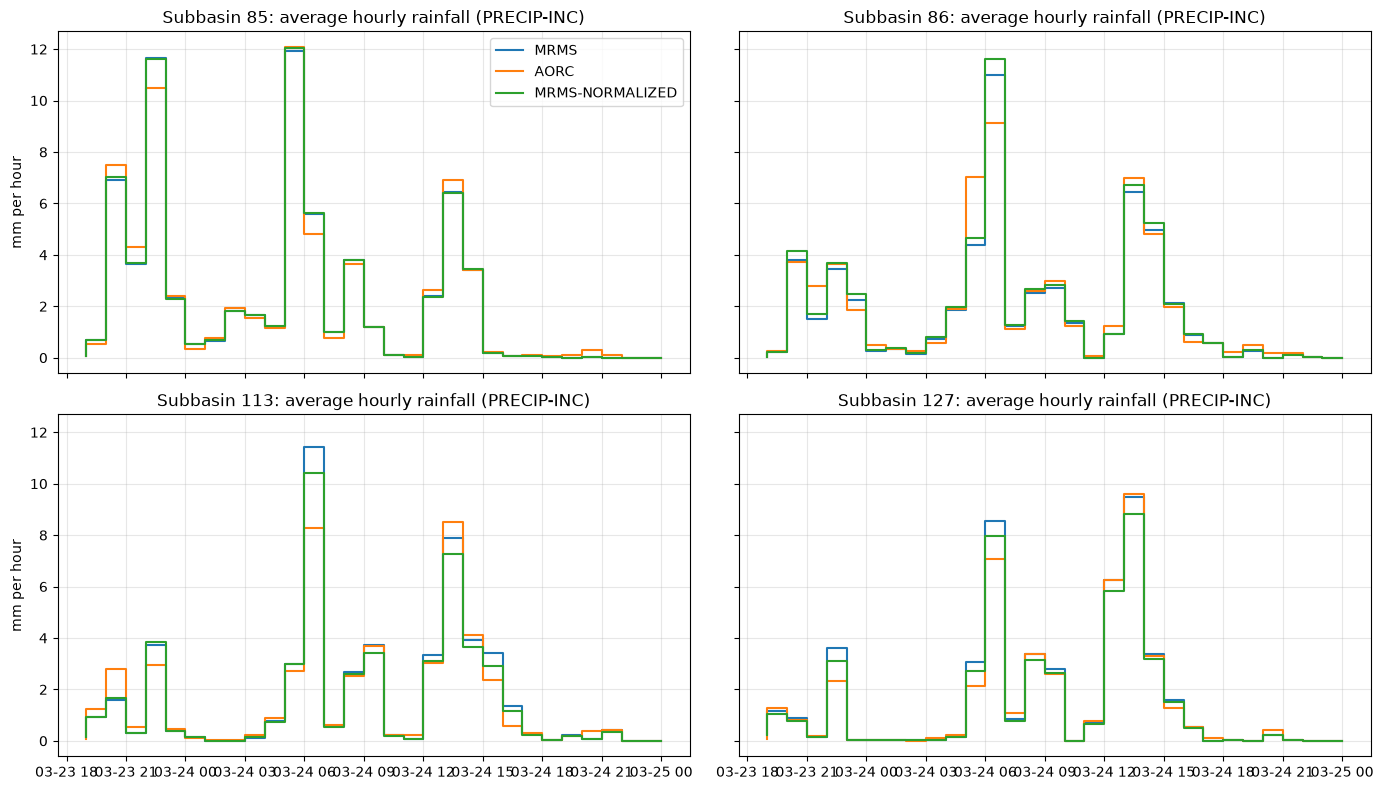

source,AORC,MRMS,MRMS-NORMALIZED
subbasin,,,
113,47.36,50.80,47.36
127,43.73,47.29,43.73
85,67.69,67.44,67.69
86,57.28,54.09,57.28


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
summary = []
for ax, zone in zip(axes.flat, sorted(masks, key=int)):
    for label, (target, res) in gages.items():
        path = next(p for p in res.pathnames if p.split("/")[2] == zone and p.split("/")[3] == "PRECIP-INC")
        ts = HmsDss.read_timeseries(target, path)
        ax.step(ts.index, ts["value"], where="pre", label=label)
        summary.append({"subbasin": zone, "source": label, "event total (mm)": ts["value"].sum()})
    ax.set_title(f"Subbasin {zone}: average hourly rainfall (PRECIP-INC)")
    ax.grid(True, alpha=0.3)
axes[0, 0].legend()
for ax in axes[:, 0]:
    ax.set_ylabel("mm per hour")
plt.tight_layout()
plt.show()
display(pd.DataFrame(summary).pivot(index="subbasin", columns="source", values="event total (mm)").round(2))

The normalized series follows MRMS hour by hour and sums to the AORC event total of
each zone. HEC-HMS can read these series as precipitation gages (`PER-CUM`, `MM`, one hour)
in a meteorologic model; that step is not run here.

### SNODAS: snow water equivalent, depth and melt

SNODAS daily files from NSIDC (data set G02158, masked to the contiguous US) are read
straight from the daily tar. The engine takes the times from the NOHRSC header by default
(`snodas_times="header"`): SWE and snow depth are instants at 06:00 UTC of the file's date,
and a daily total (precipitation, melt) is PER-CUM over the 24 hours ending then.
`snodas_times="vortex"` gives HEC-Vortex 1.1.0's timing instead, which puts each daily
total one day later and types it PER-AVER. The whole SNODAS grid is larger than one DSS
grid record can hold, so it is clipped with the envelope.

Three days of the February 2021 winter storms are used: 16 February (snow on the ground),
20 February (a deeper pack) and 22 February (melting). Each file is checked against its
SHA-256. SNODAS melt is stored in metres, as the product states; `calculate` converts it
to millimetres.

In [16]:
SNODAS = {
    "20210216": "d2897aab011e39bca8cc23d8031454c509c5a32de3d027fd7e2e6b7197d4a6eb",
    "20210220": "1ccfee59f6de95d02abaf5369f27f95ff3fd8b843f3b67fcd9e094eae8e783f4",
    "20210222": "ec3ac00d8c334ccde172b569ae56eda92a6129b9657657376730f372bba01897",
}
snow_dir = work / "snodas"
snow_dir.mkdir(exist_ok=True)
tars = []
for day, digest in SNODAS.items():
    tar = snow_dir / f"SNODAS_{day}.tar"
    if not tar.exists():
        url = (f"https://noaadata.apps.nsidc.org/NOAA/G02158/masked/{day[:4]}/"
               f"{day[4:6]}_{dt.date(int(day[:4]), int(day[4:6]), 1).strftime('%b')}/{tar.name}")
        request = urllib.request.Request(url, headers={"User-Agent": "hms-commander-example"})
        with urllib.request.urlopen(request, timeout=300) as response:
            tar.write_bytes(response.read())
    sha = hashlib.sha256(tar.read_bytes()).hexdigest()
    print(f"{tar.name}: {tar.stat().st_size / 1e6:.1f} MB, SHA-256 matches: {sha == digest}")
    assert sha == digest
    tars.append(tar)
print("Variables:", HmsDssGrid.list_variables(tars[0]))

SNODAS_20210216.tar: 34.5 MB, SHA-256 matches: True
SNODAS_20210220.tar: 35.3 MB, SHA-256 matches: True
SNODAS_20210222.tar: 31.3 MB, SHA-256 matches: True
Variables: ['Sublimation from the Snow Pack', 'Snow Melt Runoff at the Base of the Snow Pack', 'Sublimation of Blowing Snow', 'Snow Pack Average Temperature', 'Snow Depth', 'SWE', 'Solid Precipitation', 'Liquid Precipitation']


In [17]:
snow_dss = work / "snodas_header.dss"
vortex_dss = work / "snodas_vortex.dss"
for f in (snow_dss, vortex_dss):
    f.unlink(missing_ok=True)
rows = []
for variable in ("SWE", "Snow Depth", "Snow Melt Runoff at the Base of the Snow Pack",
                 "Solid Precipitation"):
    res = HmsDssGrid.import_gridded(tars, snow_dss, variable=variable, target_crs="SHG",
                                    cell_size=CELL, envelope=envelope,
                                    parts={"A": "SHG", "B": "TENK", "F": "SNODAS"})
    for rec in res.records:
        rows.append({"timing": "header (default)", "variable": variable, "pathname": rec["pathname"],
                     "type": rec["data_type"], "units": rec["units"]})
for variable in ("SWE", "Solid Precipitation"):
    res = HmsDssGrid.import_gridded(tars, vortex_dss, variable=variable, target_crs="SHG",
                                    cell_size=CELL, envelope=envelope, snodas_times="vortex",
                                    parts={"A": "SHG", "B": "TENK", "F": "SNODAS-VORTEX"})
    for rec in res.records:
        rows.append({"timing": "vortex", "variable": variable, "pathname": rec["pathname"],
                     "type": rec["data_type"], "units": rec["units"]})
display(pd.DataFrame(rows))

melt = [p for p in HmsDss.get_catalog(snow_dss) if "/LIQUID WATER/" in p]
melt_mm = work / "snodas_melt_mm.dss"
melt_mm.unlink(missing_ok=True)
converted = HmsDssGrid.calculate(snow_dss, melt_mm, multiply=1000.0, units="MM", data_type="PER-CUM", variables=melt,
                                 parts={"A": "SHG", "B": "TENK", "F": "SNODAS"})
print(f"Melt converted from {converted.records[0]['source_units']} to {converted.records[0]['units']}: "
      f"{len(converted.pathnames)} records")

try:
    HmsDssGrid.import_gridded(tars[:1], work / "snodas_refused.dss", variable="Snow Pack Average Temperature",
                              target_crs="SHG", cell_size=CELL, envelope=envelope)
except Exception as exc:
    print(f"Snow Pack Average Temperature, {type(exc).__name__}: {reason(exc)}")

,timing,variable,pathname,type,units
0,header (default),SWE,/SHG/TENK/SWE/16FEB2021:0600//SNODAS/,INST-VAL,MM
1,header (default),SWE,/SHG/TENK/SWE/20FEB2021:0600//SNODAS/,INST-VAL,MM
2,header (default),SWE,/SHG/TENK/SWE/22FEB2021:0600//SNODAS/,INST-VAL,MM
3,header (default),Snow Depth,/SHG/TENK/SNOW DEPTH/16FEB2021:0600//SNODAS/,INST-VAL,MM
4,header (default),Snow Depth,/SHG/TENK/SNOW DEPTH/20FEB2021:0600//SNODAS/,INST-VAL,MM
5,header (default),Snow Depth,/SHG/TENK/SNOW DEPTH/22FEB2021:0600//SNODAS/,INST-VAL,MM
6,header (default),Snow Melt Runoff at the Base of the Snow Pack,/SHG/TENK/LIQUID WATER/15FEB2021:0600/16FEB202...,PER-CUM,M
7,header (default),Snow Melt Runoff at the Base of the Snow Pack,/SHG/TENK/LIQUID WATER/19FEB2021:0600/20FEB202...,PER-CUM,M
8,header (default),Snow Melt Runoff at the Base of the Snow Pack,/SHG/TENK/LIQUID WATER/21FEB2021:0600/22FEB202...,PER-CUM,M
9,header (default),Solid Precipitation,/SHG/TENK/SOLID PRECIPITATION/15FEB2021:0600/1...,PER-CUM,MM


Melt converted from M to MM: 3 records
Snow Pack Average Temperature, DssUnsupportedRecordError: refused SNODAS us_ssmv11038wS__A0024TTNATS2021021605DP001.dat: product 1038 (Snow Pack Average Temperature) with time code A0024 has no qualified time and data-type interpretation (snodas_times="header", the default); to import it, name an interpretation: snodas_times="vortex" (SnodasTimes::Vortex: Vortex's file-name times and types) or snodas_times="header_as_stated" (SnodasTimes::HeaderAsStated: the header's Start and Stop as written) (0 record(s) already written remain)


zone                                           113    127     85      86
variable            units date                                          
LIQUID WATER        MM    16 Feb 2021 06:00   0.00   0.00   0.00    0.00
                          20 Feb 2021 06:00   0.00   0.00   0.00    0.00
                          22 Feb 2021 06:00   3.65   1.50   5.26    8.57
SNOW DEPTH          MM    16 Feb 2021 06:00  38.97  35.79  45.06   50.02
                          20 Feb 2021 06:00  80.28  81.06  82.47  102.42
                          22 Feb 2021 06:00   0.01   0.00   0.00    0.00
SOLID PRECIPITATION MM    16 Feb 2021 06:00   2.95   2.28   2.57    3.85
                          20 Feb 2021 06:00   0.00   0.00   0.00    0.00
                          22 Feb 2021 06:00   0.00   0.00   0.00    0.00
SWE                 MM    16 Feb 2021 06:00   4.29   4.08   5.14    5.59
                          20 Feb 2021 06:00  11.26  11.40  11.82   14.74
                          22 Feb 2021 06:00   0.00   0.00   0.00    0.00

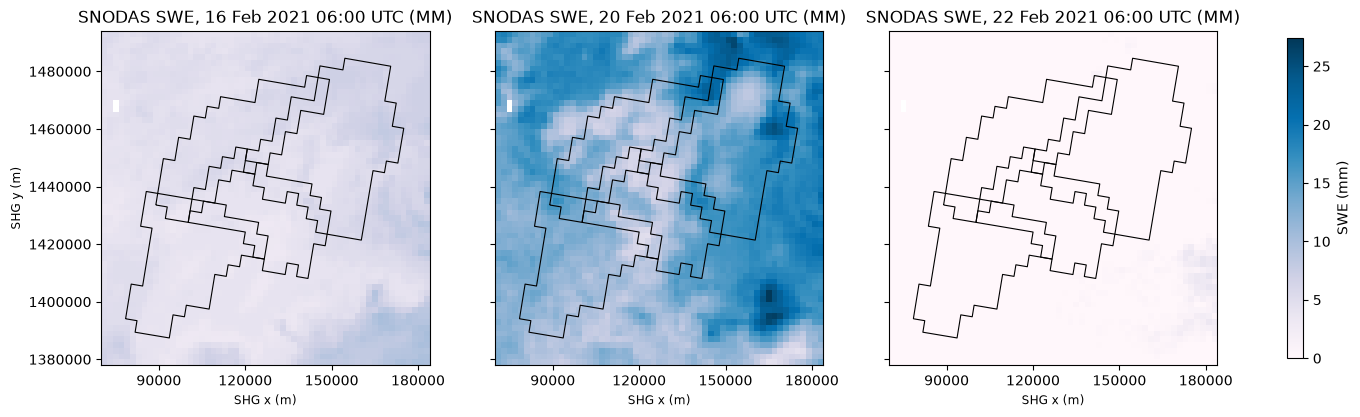

In [18]:
snow = pd.concat([HmsDssGrid.zonal_statistics(snow_dss, zones_file, "NAME",
                                              variables=[p for p in HmsDss.get_catalog(snow_dss)
                                                         if "/LIQUID WATER/" not in p]),
                  HmsDssGrid.zonal_statistics(melt_mm, zones_file, "NAME")])
snow["date"] = snow["end"].dt.strftime("%d %b %Y %H:%M")
pivot = snow.pivot_table(index=["variable", "units", "date"], columns="zone", values="average")
display(pivot.round(2))

swe = [p for p in HmsDss.get_catalog(snow_dss) if "/SWE/" in p]
fig, axes = plt.subplots(1, len(swe), figsize=(6 * len(swe), 5.2), sharey=True)
axes = np.atleast_1d(axes)
vmax = max(np.nanmax(HmsDss.read_grid(snow_dss, p)["data"]) for p in swe)
for ax, p in zip(axes, swe):
    g = HmsDss.read_grid(snow_dss, p)
    x0, y0 = g["lower_left_cell"][0] * CELL, g["lower_left_cell"][1] * CELL
    ny, nx = g["shape"]
    im = ax.imshow(g["data"], origin="lower", extent=(x0, x0 + nx * CELL, y0, y0 + ny * CELL),
                   cmap="PuBu", vmin=0, vmax=vmax)
    zones.boundary.plot(ax=ax, color="k", linewidth=0.8)
    ax.set_title(f"SNODAS SWE, {g['start_time']:%d %b %Y %H:%M} UTC ({g['units']})")
    ax.set_xlabel("SHG x (m)")
    ax.set_ylabel("")
    ax.ticklabel_format(style="plain")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
axes[0].set_ylabel("SHG y (m)")
fig.colorbar(im, ax=axes, shrink=0.8, label="SWE (mm)")
plt.show()

## Summary

| Step | `HmsDssGrid` method | Shown with |
|---|---|---|
| What a file offers | `list_variables` | MRMS GRIB2, AORC NetCDF-4, SNODAS tar |
| Import to SHG | `import_gridded` | MRMS 1-hour, 6-hour and 24-hour; AORC; SNODAS |
| Accumulation windows | `import_gridded(window_rule="accumulation:06H")` | MRMS 6-hour and 24-hour |
| Clip at import | `envelope=`, `shapefile=` (bounding box) | tenk zones |
| Resampling, threads | `method=`, `threads=` | near, bilinear, average; all cores and one |
| Sanitizer, calculators | `sanitize`, `calculate`, `calculate_raster` | MRMS, AORC daily totals |
| Clipper | `clip` | subbasin 86 |
| Normalizer | `normalize` | MRMS pattern, AORC totals |
| Time tools | `shift_times`, `resample_times`, `time_steps` | -6 h; 3-hour and daily |
| Reads | `series_info`, `read_window`, `read_nearest`, `read_min_max` | MRMS |
| Zonal | `zone_masks`, `zonal_statistics`, `grid_to_point` | all eight statistics |

**Not shown here, and why**

- **HRRR forecasts and NCEP Stage IV**: hms-commander has no downloader for archived HRRR
  cycles (each full file is about 165 MB) or for Stage IV, and the HRRR downloader in
  ras-commander reads NOAA's rolling NOMADS archive, which keeps only recent cycles. The
  engine reads both (Stage IV GRIB1 for 2002 to July 2020, and GRIB2).
- **HDF5, GeoTIFF, ASCII grids, PRISM and local Zarr v2 stores**: the engine reads them;
  this notebook has no public file of these kinds for the tenk basin.
- **HEC-HMS acceptance of the gage series**: see notebook 14c for an HEC-HMS run that is
  checked against the grids it reads.

See the [native DSS backend guide](../user_guide/dss_native_backend.md) for every option,
and `help(ras_commander_fast_dss.gridded.import_gridded)` for the engine's reference.